# Text Preprocessing and Word2Vec Analysis Using the Brown Corpus
**Student Name:** Surya Prasad M                                         
**Roll Number:** 24BAD119           


## Part A — Dataset Preparation and Text Preprocessing
Load the Brown Corpus's **news** category, inspect sample sentences, lowercase and tokenize the text, remove punctuation and stop words, and lemmatize using WordNetLemmatizer.

In [5]:
%pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 50.7 MB/s eta 0:00:00


In [6]:
import re
import nltk
import pandas as pd
import matplotlib.pyplot as plt
from nltk.corpus import brown, stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk import FreqDist
from gensim.models import Word2Vec
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

In [7]:
for resource in ["brown", "punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource)

print("NLTK resources are ready.")

[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Unzipping corpora/brown.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


NLTK resources are ready.


In [8]:
CATEGORY = "news"
sentences = brown.sents(categories=CATEGORY)
print("Selected category:", CATEGORY)
print("Number of sentences:", len(sentences))
print("\nSample original sentences:")
for i, sentence in enumerate(sentences[:5], start=1):
    print(f"{i}. {' '.join(sentence)}")

Selected category: news
Number of sentences: 4623

Sample original sentences:
1. The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place .
2. The jury further said in term-end presentments that the City Executive Committee , which had over-all charge of the election , `` deserves the praise and thanks of the City of Atlanta '' for the manner in which the election was conducted .
3. The September-October term jury had been charged by Fulton Superior Court Judge Durwood Pye to investigate reports of possible `` irregularities '' in the hard-fought primary which was won by Mayor-nominate Ivan Allen Jr. .
4. `` Only a relative handful of such reports was received '' , the jury said , `` considering the widespread interest in the election , the number of voters and the size of this city '' .
5. The jury said it did find that many of Georgia's registration and election laws `` are outmoded or

In [9]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_sentence(tokens):
    text = " ".join(tokens).lower()
    tokens_lower = word_tokenize(text)
    processed = []
    for token in tokens_lower:
        if token.isalpha() and token not in stop_words:
            processed.append(lemmatizer.lemmatize(token))
    return processed

processed_sentences = [preprocess_sentence(s) for s in sentences]
processed_sentences = [s for s in processed_sentences if s]

for i in range(5):
    print(f"Example {i + 1}")
    print("Original:     ", " ".join(sentences[i]))
    print("Preprocessed: ", " ".join(processed_sentences[i]))
    print("-" * 80)

Example 1
Original:      The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place .
Preprocessed:  fulton county grand jury said friday investigation atlanta recent primary election produced evidence irregularity took place
--------------------------------------------------------------------------------
Example 2
Original:      The jury further said in term-end presentments that the City Executive Committee , which had over-all charge of the election , `` deserves the praise and thanks of the City of Atlanta '' for the manner in which the election was conducted .
Preprocessed:  jury said presentment city executive committee charge election deserves praise thanks city atlanta manner election conducted
--------------------------------------------------------------------------------
Example 3
Original:      The September-October term jury had been charged by Fulton Superior Court Judge Durw

## Part B — Vocabulary Generation and Word Frequency Analysis
Build the vocabulary and use `nltk.FreqDist` to find the ten most frequent words. Keep sentence boundaries for Word2Vec training.

In [10]:
all_tokens = [word for sentence in processed_sentences for word in sentence]
frequency_distribution = FreqDist(all_tokens)
vocabulary = set(all_tokens)

print("Total token count:", len(all_tokens))
print("Vocabulary size (unique words):", len(vocabulary))
print("\nTen most frequent words:")
for word, count in frequency_distribution.most_common(10):
    print(f"{word}: {count}")

frequency_table = pd.DataFrame(
    frequency_distribution.most_common(20),
    columns=["Word", "Frequency"]
)
display(frequency_table)

Total token count: 47682
Vocabulary size (unique words): 9896

Ten most frequent words:
said: 406
year: 260
would: 249
new: 241
state: 223
one: 222
last: 177
two: 174
first: 158
president: 155


,Word,Frequency
0,said,406
1,year,260
2,would,249
3,new,241
4,state,223
5,one,222
6,last,177
7,two,174
8,first,158
9,president,155


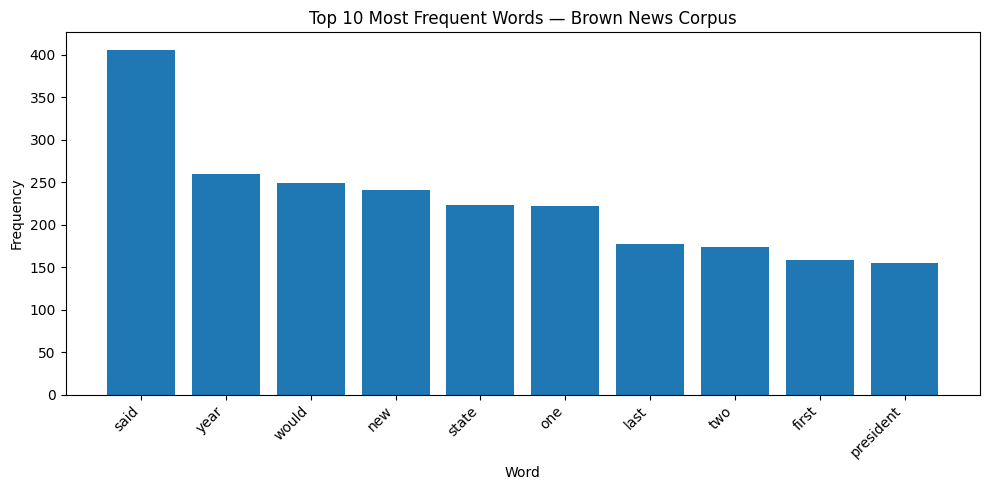

Prepared sentence count for Word2Vec: 4590
Example tokenized sentence: ['fulton', 'county', 'grand', 'jury', 'said', 'friday', 'investigation', 'atlanta', 'recent', 'primary', 'election', 'produced', 'evidence', 'irregularity', 'took', 'place']


In [11]:
top10 = frequency_distribution.most_common(10)
words = [item[0] for item in top10]
counts = [item[1] for item in top10]

plt.figure(figsize=(10, 5))
plt.bar(words, counts)
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.title("Top 10 Most Frequent Words — Brown News Corpus")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("Prepared sentence count for Word2Vec:", len(processed_sentences))
print("Example tokenized sentence:", processed_sentences[0])

## Part C — Word Embedding Generation Using Word2Vec
Train Gensim Word2Vec with Skip-gram (`sg=1`), vector size 100, and context window 5. A fixed seed improves reproducibility, although exact results can vary across environments.

In [12]:
VECTOR_SIZE = 100
WINDOW_SIZE = 5
MIN_COUNT = 2
EPOCHS = 10

word2vec_model = Word2Vec(
    sentences=processed_sentences,
    vector_size=VECTOR_SIZE,
    window=WINDOW_SIZE,
    min_count=MIN_COUNT,
    workers=1,
    sg=1,
    seed=42,
    epochs=EPOCHS
)

print("Word2Vec model training complete.")
print("Vocabulary learned by Word2Vec:", len(word2vec_model.wv))
print("Vector dimension:", word2vec_model.wv.vector_size)

Word2Vec model training complete.
Vocabulary learned by Word2Vec: 5164
Vector dimension: 100


In [13]:
selected_word = None
for candidate in ["government", "year", "state", "people", "new", "one", "man"]:
    if candidate in word2vec_model.wv:
        selected_word = candidate
        break
if selected_word is None:
    selected_word = word2vec_model.wv.index_to_key[0]

embedding_vector = word2vec_model.wv[selected_word]
print("Selected word:", selected_word)
print("Embedding vector:")
print(embedding_vector)
print("Vector shape:", embedding_vector.shape)
print("Number of dimensions:", len(embedding_vector))

print(f"\nFive most similar words to '{selected_word}':")
for word, score in word2vec_model.wv.most_similar(selected_word, topn=5):
    print(f"{word}: {score:.4f}")

Selected word: government
Embedding vector:
[-0.03939539 -0.01844642  0.11237339  0.18734224 -0.07713591 -0.02296403
  0.23091821  0.2165161   0.1408525  -0.2891347  -0.33996132  0.01070116
 -0.01228927  0.38651592 -0.15578407 -0.22136436  0.00841898 -0.15307482
 -0.25506952  0.22462574  0.04277756  0.18880297 -0.01265004  0.06385567
 -0.00375846  0.0184399  -0.1728565   0.3096049  -0.13759232 -0.14902957
 -0.13589548 -0.11846808  0.09864164  0.11621501  0.10893569 -0.17349473
  0.19579786 -0.23722145 -0.12336223 -0.03413454  0.01806677 -0.0924122
  0.0847496  -0.21629116  0.04230527  0.01971324  0.3145833   0.26387477
  0.29094037 -0.35780343 -0.11155628 -0.22519663 -0.05564813  0.0802375
  0.04740578  0.10098162 -0.17702778 -0.00358262 -0.03867766  0.11865263
  0.00569936  0.01556148 -0.18841194  0.06478949  0.05729983  0.0842135
 -0.05820354 -0.12878728 -0.3851275  -0.08134852 -0.04647505  0.04165713
 -0.15234418 -0.16747324  0.07555635  0.04707142  0.12524785 -0.17830327
 -0.067390

## Part D — Word Similarity Analysis and Experiment Management
Select three word pairs available in the learned vocabulary, calculate cosine similarity, compare scores, and interpret contextual relationships.

In [14]:
candidate_pairs = [
    ("government", "state"),
    ("president", "official"),
    ("city", "country"),
    ("company", "business"),
    ("school", "student"),
    ("market", "business"),
    ("people", "man"),
    ("year", "month"),
    ("american", "national"),
]

selected_pairs = []
for w1, w2 in candidate_pairs:
    if w1 in word2vec_model.wv and w2 in word2vec_model.wv and w1 != w2:
        selected_pairs.append((w1, w2))
    if len(selected_pairs) == 3:
        break

if len(selected_pairs) < 3:
    common_words = word2vec_model.wv.index_to_key
    for i in range(min(30, len(common_words))):
        for j in range(i + 1, min(30, len(common_words))):
            pair = (common_words[i], common_words[j])
            if pair not in selected_pairs:
                selected_pairs.append(pair)
            if len(selected_pairs) == 3:
                break
        if len(selected_pairs) == 3:
            break

similarity_results = []
for w1, w2 in selected_pairs:
    score = float(word2vec_model.wv.similarity(w1, w2))
    direct_score = float(cosine_similarity(
        word2vec_model.wv[w1].reshape(1, -1),
        word2vec_model.wv[w2].reshape(1, -1)
    )[0, 0])
    similarity_results.append({
        "Word 1": w1,
        "Word 2": w2,
        "Cosine similarity": score,
        "Direct cosine check": direct_score
    })

similarity_df = pd.DataFrame(similarity_results).sort_values(
    "Cosine similarity", ascending=False
).reset_index(drop=True)
display(similarity_df)

if not similarity_df.empty:
    best = similarity_df.iloc[0]
    print(
        f"Most similar selected pair: '{best['Word 1']}' and '{best['Word 2']}' "
        f"(cosine similarity = {best['Cosine similarity']:.4f})"
    )

,Word 1,Word 2,Cosine similarity,Direct cosine check
0,government,state,0.915617,0.915617
1,city,country,0.909577,0.909577
2,president,official,0.830586,0.830586


Most similar selected pair: 'government' and 'state' (cosine similarity = 0.9156)
